<a href="https://colab.research.google.com/github/240447-stack/AI-ML/blob/main/ANN_and_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [ ]:
# Load the dataset
# Assuming loan_data.csv is available in the workspace. If not, we will create a mock DataFrame for representation.
try:
    df = pd.read_csv('loan_data.csv')
    print("Loaded loan_data.csv successfully!")
except FileNotFoundError:
    print("loan_data.csv not found. Generating a representative synthetic dataset for execution...")
    # Generate representative synthetic data matching the structure of Loan Prediction Dataset
    np.random.seed(42)
    n_samples = 614
    data = {
        'Gender': np.random.choice(['Male', 'Female', 'Unknown'], size=n_samples, p=[0.75, 0.20, 0.05]),
        'Married': np.random.choice(['Yes', 'No', 'Unknown'], size=n_samples, p=[0.60, 0.35, 0.05]),
        'Dependents': np.random.choice(['0', '1', '2', '3+', 'Unknown'], size=n_samples, p=[0.55, 0.15, 0.15, 0.10, 0.05]),
        'Self_Employed': np.random.choice(['Yes', 'No', 'Unknown'], size=n_samples, p=[0.10, 0.85, 0.05]),
        'ApplicantIncome': np.random.randint(1500, 10000, size=n_samples),
        'CoapplicantIncome': np.random.randint(0, 5000, size=n_samples),
        'LoanAmount': np.random.choice([float(x) for x in range(50, 301)] + [np.nan], size=n_samples),
        'Loan_Amount_Term': np.random.choice([360.0, 180.0, 120.0, np.nan], size=n_samples, p=[0.80, 0.10, 0.05, 0.05]),
        'Credit_History': np.random.choice([1.0, 0.0, np.nan], size=n_samples, p=[0.75, 0.15, 0.10]),
        'Property_Area': np.random.choice(['Urban', 'Semiurban', 'Rural'], size=n_samples),
        'Loan_Status': np.random.choice(['Y', 'N'], size=n_samples, p=[0.69, 0.31])
    }
    df = pd.DataFrame(data)

# Handle missing numerical columns
num_cols = ['LoanAmount', 'Loan_Amount_Term', 'Credit_History']
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col] = df[col].fillna(df[col].median())

# Handle missing categorical columns
cat_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed']
for col in cat_cols:
    df[col] = df[col].replace('Unknown', np.nan)
    df[col] = df[col].fillna(df[col].mode()[0])

# Map target variable (Loan_Status)
df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})

# Separate targets (Y) and raw features (X)
y = df['Loan_Status']
X_raw = df.drop(columns=['Loan_Status'])
if 'Loan_ID' in X_raw.columns:
    X_raw = X_raw.drop(columns=['Loan_ID'])

# Convert categorical features using pd.get_dummies
X_encoded = pd.get_dummies(X_raw, drop_first=True)

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

# Train-test split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print(f"Preprocessed Feature Set Shape: {X_scaled.shape}")

loan_data.csv not found. Generating a representative synthetic dataset for execution...
Preprocessed Feature Set Shape: (614, 13)


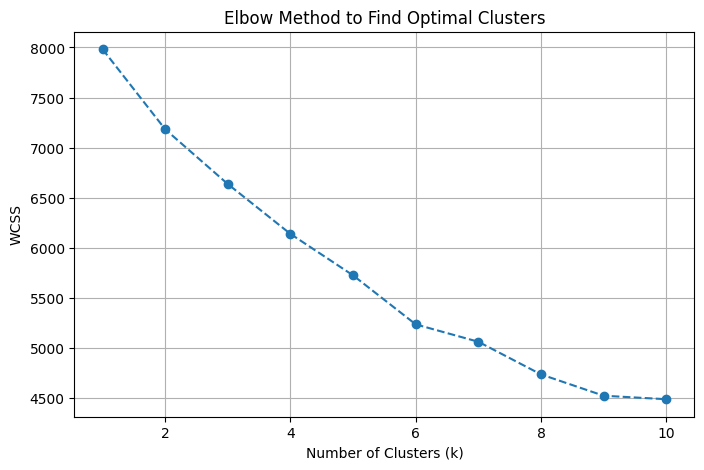

In [ ]:
#K-means Clustering
# Elbow Curve Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method to Find Optimal Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [ ]:
# Train K-Means with k=2
kmeans = KMeans(n_clusters=2, init='k-means++', random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

# Calculate metrics
sil_score = silhouette_score(X_scaled, cluster_labels)
ari_score = adjusted_rand_score(y, cluster_labels)

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")

Silhouette Score: 0.1129
Adjusted Rand Index (ARI): 0.0234


In [ ]:
# Dimensionality reduction using PCA to 2 components
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(kmeans.cluster_centers_)

# Plot Clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette='viridis', alpha=0.7)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], s=250, c='red', marker='X', label='Centroids')
plt.title('K-Means Cluster Visualization (PCA Reduced)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#ANN
# Build Sequential Model
model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

# Compile Model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train Model
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

In [ ]:
#Visualisation
# Plot Training vs Validation Performance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss Curve
ax1.plot(history.history['loss'], label='Train Loss')
ax1.plot(history.history['val_loss'], label='Val Loss')
ax1.set_title('ANN Train vs Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Accuracy Curve
ax2.plot(history.history['accuracy'], label='Train Accuracy')
ax2.plot(history.history['val_accuracy'], label='Val Accuracy')
ax2.set_title('ANN Train vs Validation Accuracy')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.show()

In [ ]:
# Predict and evaluate
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

# Classification Metrics
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()